# A Business Approach to Fantasy Football
### Player Valuation and Risk Analysis Using Python

**Project Overview**

This project uses Python and NFL fantasy football statistics to evaluate players as investments. By comparing preseason draft positions with actual player performance, I aim to identify which players provide the greatest value relative to their draft cost.

The model evaluates players using three factors:

- **Production (50%):** How much value a player produces above replacement level.
- **Draft Overperformance (30%):** How much a player exceeds expectations based on draft position.
- **Bargain Value (20%):** How efficiently a player produces relative to their draft cost.

The investment rankings focus on players who are producing above replacement level at their position. Players below replacement level are excluded because they are not currently providing positive value compared to a typical replacement option. As a result, these rankings represent the best positive-value investments rather than every player in the NFL.

The goal is to apply business concepts such as valuation, return on investment, and risk analysis to fantasy football decision-making.

## 1. Data Collection

In [363]:

import nflreadpy as nfl
import pandas as pd

# Download 2026 NFL player statistics
df = nfl.load_player_stats(seasons=[2026]).to_pandas()

# Display the first five rows
df.head()


,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,12.54,12.54
1,00-0025565,N.Folk,Nick Folk,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,0.00,0.00
2,00-0026190,C.Campbell,Calais Campbell,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_BAL_IND,...,0,0,0,0,0,0,0,0,0.00,0.00
3,00-0026498,M.Stafford,Matthew Stafford,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_SF_LA,...,0,0,0,0,0,0,0,0,4.10,4.10
4,00-0027969,C.Heyward,Cameron Heyward,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,0.00,0.00


In [364]:

# Keep only regular season fantasy players
fantasy_df = df[
    (df["season_type"] == "REG") &
    (df["position"].isin(["QB", "RB", "WR", "TE"]))
].copy()

# Group each player's weekly stats together
player_stats = fantasy_df.groupby(
    ["player_id", "player_display_name", "position"]
).agg(
    games_played=("week", "nunique"),
    total_points=("fantasy_points_ppr", "sum"),
    avg_points=("fantasy_points_ppr", "mean")
).reset_index()

# Sort players by average fantasy points
player_stats = player_stats.sort_values(
    "avg_points", ascending=False
)

# Show the top 20 players
player_stats.head(20)


,player_id,player_display_name,position,games_played,total_points,avg_points
300,00-0039139,Jahmyr Gibbs,RB,5,153.70,30.740000
232,00-0038134,Kenneth Walker III,RB,5,138.00,27.600000
247,00-0038543,Jaxon Smith-Njigba,WR,6,164.86,27.476667
78,00-0034857,Josh Allen,QB,6,161.26,26.876667
30,00-0033106,Jared Goff,QB,5,115.00,23.000000
298,00-0039075,Puka Nacua,WR,4,91.80,22.950000
217,00-0037834,Brock Purdy,QB,6,134.00,22.333333
302,00-0039150,Bryce Young,QB,5,110.46,22.092000
128,00-0036358,CeeDee Lamb,WR,6,131.10,21.850000
246,00-0038542,Bijan Robinson,RB,6,128.50,21.416667


## 2. Player Performance and Draft Value

In [365]:

# Only include players with at least 3 games
player_stats = player_stats[
    player_stats["games_played"] >= 3
].copy()

# Rank players within their positions
player_stats["position_rank"] = (
    player_stats.groupby("position")["avg_points"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Sort by position and rank
player_stats = player_stats.sort_values(
    ["position", "position_rank"]
)

# Display top 15 running backs
rb_stats = player_stats[
    player_stats["position"] == "RB"
]

rb_stats.head(15)


,player_id,player_display_name,position,games_played,total_points,avg_points,position_rank
300,00-0039139,Jahmyr Gibbs,RB,5,153.7,30.740000,1
232,00-0038134,Kenneth Walker III,RB,5,138.0,27.600000,2
246,00-0038542,Bijan Robinson,RB,6,128.5,21.416667,3
35,00-0033280,Christian McCaffrey,RB,6,122.0,20.333333,4
219,00-0037840,Kyren Williams,RB,6,119.0,19.833333,5
116,00-0036223,Jonathan Taylor,RB,6,118.5,19.750000,6
139,00-0036555,Chuba Hubbard,RB,5,98.1,19.620000,7
24,00-0032764,Derrick Henry,RB,6,116.8,19.466667,8
185,00-0037248,James Cook,RB,6,113.6,18.933333,9
169,00-0036997,Javonte Williams,RB,6,109.0,18.166667,10


In [366]:

# Create our player valuation table
valuation_df = player_stats[
    ["player_id", "player_display_name",
     "position", "games_played",
     "avg_points", "position_rank"]
].copy()

# Rename columns to make them easier to understand
valuation_df = valuation_df.rename(columns={
    "player_display_name": "player",
    "avg_points": "points_per_game",
    "position_rank": "actual_rank"
})

# Display our table
valuation_df.head(15)


,player_id,player,position,games_played,points_per_game,actual_rank
78,00-0034857,Josh Allen,QB,6,26.876667,1
30,00-0033106,Jared Goff,QB,5,23.000000,2
217,00-0037834,Brock Purdy,QB,6,22.333333,3
302,00-0039150,Bryce Young,QB,5,22.092000,4
357,00-0039910,Jayden Daniels,QB,4,21.415000,5
361,00-0039918,Caleb Williams,QB,3,20.493333,6
135,00-0036442,Joe Burrow,QB,5,20.248000,7
70,00-0034796,Lamar Jackson,QB,4,19.770000,8
164,00-0036971,Trevor Lawrence,QB,6,19.033333,9
53,00-0033873,Patrick Mahomes,QB,5,18.812000,10


In [367]:

# Load our fantasy draft data
adp_df = pd.read_csv("FantasyPros_2026_Overall_ADP_Rankings.csv")

# Look at the first 10 players
adp_df.head(10)


,Rank,Player (Bye),POS,Sleeper,RTSports,AVG,Real-Time
0,1,Jahmyr Gibbs DET (6),RB1,2.0,1.0,1.5,1
1,2,Bijan Robinson ATL (11),RB2,1.0,2.0,1.5,2
2,3,Ja'Marr Chase CIN (6),WR1,6.0,3.0,4.5,3
3,4,Christian McCaffrey SF (8),RB3,4.0,5.0,4.5,6 -2
4,5,Jonathan Taylor IND (13),RB4,3.0,7.0,5.0,4 +1
5,6,Puka Nacua LAR (11),WR2,9.0,4.0,6.5,5 +1
6,7,James Cook III BUF (7),RB5,5.0,8.0,6.5,7
7,8,Jaxon Smith-Njigba SEA (11),WR3,10.0,6.0,8.0,9 -1
8,9,De'Von Achane MIA (6),RB6,8.0,10.0,9.0,15 -6
9,10,Omarion Hampton LAC (7),RB7,12.0,13.0,12.5,17 -7


In [368]:

# Remove team abbreviations and bye weeks
adp_df["player"] = adp_df["Player (Bye)"].str.replace(
    r"\s+[A-Z]{2,3}\s+\(\d+\)$", "", regex=True
)

# Extract the position (RB, WR, QB, TE)
adp_df["position"] = adp_df["POS"].str.extract(
    r"([A-Z]+)"
)

# Extract the draft rank within each position
adp_df["draft_rank"] = adp_df["POS"].str.extract(
    r"(\d+)"
).astype(int)

# Display the cleaned data
adp_df[["player", "position", "draft_rank", "AVG"]].head(15)


,player,position,draft_rank,AVG
0,Jahmyr Gibbs,RB,1,1.5
1,Bijan Robinson,RB,2,1.5
2,Ja'Marr Chase,WR,1,4.5
3,Christian McCaffrey,RB,3,4.5
4,Jonathan Taylor,RB,4,5.0
5,Puka Nacua,WR,2,6.5
6,James Cook III,RB,5,6.5
7,Jaxon Smith-Njigba,WR,3,8.0
8,De'Von Achane,RB,6,9.0
9,Omarion Hampton,RB,7,12.5


In [369]:

# Combine performance data with draft data
merged_df = valuation_df.merge(
    adp_df[["player", "position", "draft_rank", "AVG"]],
    on=["player", "position"],
    how="inner"
)

# Calculate how much each player exceeded draft expectations
merged_df["value_score"] = (
    merged_df["draft_rank"] - merged_df["actual_rank"]
)

# Sort from biggest draft steals to biggest disappointments
merged_df = merged_df.sort_values(
    "value_score", ascending=False
)

# Display the results
merged_df[
    ["player", "position", "draft_rank",
     "actual_rank", "value_score", "points_per_game"]
].head(20)


,player,position,draft_rank,actual_rank,value_score,points_per_game
47,Ollie Gordon II,RB,91,20,71,12.000000
173,Germie Bernard,WR,92,39,53,10.620000
171,Keon Coleman,WR,89,37,52,10.883333
172,Jaylin Noel,WR,90,38,52,10.833333
166,Devaughn Vele,WR,82,31,51,11.566667
68,Roschon Johnson,RB,93,43,50,6.700000
66,Ty Johnson,RB,88,41,47,7.025000
71,Devin Singletary,RB,90,46,44,6.333333
149,Matthew Golden,WR,54,14,40,16.783333
57,Emanuel Wilson,RB,70,31,39,9.383333


In [370]:

# Define fantasy starter thresholds
starter_limits = {
    "QB": 12,
    "RB": 24,
    "WR": 24,
    "TE": 12
}

# Identify players performing at starter level
merged_df["starter_limit"] = merged_df["position"].map(
    starter_limits
)

starters_df = merged_df[
    merged_df["actual_rank"] <= merged_df["starter_limit"]
].copy()

# Rank the best values among fantasy starters
starters_df = starters_df.sort_values(
    "value_score", ascending=False
)

# Show our results
starters_df[
    ["player", "position", "draft_rank",
     "actual_rank", "value_score", "points_per_game"]
].head(20)


,player,position,draft_rank,actual_rank,value_score,points_per_game
47,Ollie Gordon II,RB,91,20,71,12.000000
149,Matthew Golden,WR,54,14,40,16.783333
148,Jalen Coker,WR,52,13,39,16.975000
159,Tre Tucker,WR,63,24,39,13.083333
107,Mike Gesicki,TE,37,7,30,12.975000
51,Alvin Kamara,RB,52,24,28,10.520000
157,Stefon Diggs,WR,47,22,25,13.880000
36,Chuba Hubbard,RB,32,7,25,19.620000
111,Pat Freiermuth,TE,35,11,24,10.566667
3,Bryce Young,QB,26,4,22,22.092000


## 3. Data Cleaning and Improved Player Matching

In [371]:

import re
import unicodedata

# Create a function to standardize player names
def clean_name(name):
    name = unicodedata.normalize("NFKD", str(name))
    name = name.encode("ascii", "ignore").decode("ascii")
    name = name.lower()
    name = re.sub(r"\b(jr|sr|ii|iii|iv)\b", "", name)
    name = re.sub(r"[^a-z0-9]", "", name)
    return name

# Apply the function to both datasets
valuation_df["clean_name"] = valuation_df["player"].apply(clean_name)
adp_df["clean_name"] = adp_df["player"].apply(clean_name)

# Match players using standardized names and positions
clean_merged = valuation_df.merge(
    adp_df[["clean_name", "position", "draft_rank", "AVG"]],
    on=["clean_name", "position"],
    how="inner"
)

# Check our new match rate
eligible_adp = adp_df[
    adp_df["position"].isin(["QB", "RB", "WR", "TE"])
]

print("Original matches:", len(merged_df))
print("New matches:", len(clean_merged))
print("Eligible drafted players:", len(eligible_adp))
print(
    "New match rate:",
    round(len(clean_merged) / len(eligible_adp) * 100, 1),
    "%"
)

# Preview matched players
clean_merged[
    ["player", "position", "draft_rank", "points_per_game"]
].head(10)


Original matches: 220
New matches: 229
Eligible drafted players: 279
New match rate: 82.1 %


,player,position,draft_rank,points_per_game
0,Josh Allen,QB,1,26.876667
1,Jared Goff,QB,16,23.000000
2,Brock Purdy,QB,13,22.333333
3,Bryce Young,QB,26,22.092000
4,Jayden Daniels,QB,5,21.415000
5,Caleb Williams,QB,7,20.493333
6,Joe Burrow,QB,4,20.248000
7,Lamar Jackson,QB,2,19.770000
8,Trevor Lawrence,QB,9,19.033333
9,Patrick Mahomes,QB,12,18.812000


In [372]:

# Recalculate performance without the 3-game minimum
all_player_stats = fantasy_df.groupby(
    ["player_id", "player_display_name", "position"]
).agg(
    games_played=("week", "nunique"),
    total_points=("fantasy_points_ppr", "sum"),
    avg_points=("fantasy_points_ppr", "mean")
).reset_index()

# Create a cleaned player name for matching
all_player_stats["clean_name"] = (
    all_player_stats["player_display_name"].apply(clean_name)
)

# Merge with our draft data
all_players_merged = eligible_adp.merge(
    all_player_stats,
    on=["clean_name", "position"],
    how="left"
)

# Check how many drafted players now have performance data
print("Eligible drafted players:", len(eligible_adp))
print(
    "Players with NFL data:",
    all_players_merged["player_id"].notna().sum()
)
print(
    "Players without NFL data:",
    all_players_merged["player_id"].isna().sum()
)

# Preview players with limited games
all_players_merged[
    all_players_merged["games_played"] < 3
][
    ["player", "position", "draft_rank",
     "games_played", "total_points"]
].head(15)


Eligible drafted players: 279
Players with NFL data: 256
Players without NFL data: 23


,player,position,draft_rank,games_played,total_points
23,A.J. Brown,WR,8,2.0,11.30
89,Jordan Mason,RB,36,1.0,11.90
92,Jaxson Dart,QB,11,2.0,27.40
95,Alec Pierce,WR,39,2.0,12.20
116,Jonathon Brooks,RB,43,2.0,9.30
117,Jayden Reed,WR,46,2.0,6.40
124,Jonah Coleman,RB,46,2.0,14.80
143,Dylan Sampson,RB,53,1.0,0.00
160,David Njoku,TE,25,2.0,12.70
162,Ja'Kobi Lane,WR,59,2.0,10.10


In [373]:

# Keep all drafted players, including those with no games
final_df = all_players_merged.copy()

# Identify players with recorded NFL statistics
final_df["has_played"] = final_df["games_played"].fillna(0) > 0

# Calculate production across all observed weeks
total_weeks = fantasy_df["week"].nunique()

final_df["total_points"] = final_df["total_points"].fillna(0)

final_df["points_per_week"] = (
    final_df["total_points"] / total_weeks
)

# Create our performance analysis using players who played
active_df = final_df[final_df["has_played"]].copy()

print("Total drafted players:", len(final_df))
print("Players with games:", len(active_df))
print("Players with zero games:", (~final_df["has_played"]).sum())

active_df[
    ["player", "position", "draft_rank",
     "games_played", "total_points", "points_per_week"]
].head(10).round(2)


Total drafted players: 279
Players with games: 256
Players with zero games: 23


,player,position,draft_rank,games_played,total_points,points_per_week
0,Jahmyr Gibbs,RB,1,5.0,153.70,25.62
1,Bijan Robinson,RB,2,6.0,128.50,21.42
2,Ja'Marr Chase,WR,1,5.0,79.90,13.32
3,Christian McCaffrey,RB,3,6.0,122.00,20.33
4,Jonathan Taylor,RB,4,6.0,118.50,19.75
5,Puka Nacua,WR,2,4.0,91.80,15.30
6,James Cook III,RB,5,6.0,113.60,18.93
7,Jaxon Smith-Njigba,WR,3,6.0,164.86,27.48
8,De'Von Achane,RB,6,3.0,24.60,4.10
9,Omarion Hampton,RB,7,6.0,57.50,9.58


In [374]:

# Rank players by production across the observed season
active_df["updated_rank"] = (
    active_df.groupby("position")["points_per_week"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Compare draft rank with updated performance rank
active_df["updated_value_score"] = (
    active_df["draft_rank"] - active_df["updated_rank"]
)

# Show the biggest improvements among top performers
top_performers = active_df[
    (
        ((active_df["position"] == "QB") |
         (active_df["position"] == "TE")) &
        (active_df["updated_rank"] <= 12)
    ) |
    (
        ((active_df["position"] == "RB") |
         (active_df["position"] == "WR")) &
        (active_df["updated_rank"] <= 24)
    )
].copy()

top_performers.sort_values(
    "updated_value_score", ascending=False
)[
    ["player", "position", "draft_rank",
     "updated_rank", "updated_value_score",
     "points_per_week"]
].head(20).round(2)


,player,position,draft_rank,updated_rank,updated_value_score,points_per_week
203,Emanuel Wilson,RB,70,22,48,9.38
149,Matthew Golden,WR,54,8,46,16.78
172,Tre Tucker,WR,63,18,45,13.08
158,Denzel Boston,WR,58,22,36,11.92
151,Braelon Allen,RB,56,21,35,9.48
275,Michael Mayer,TE,41,10,31,10.10
229,Kirk Cousins,QB,35,7,28,18.51
240,Pat Freiermuth,TE,35,8,27,10.57
63,Christian Watson,WR,27,3,24,19.80
97,Aaron Jones Sr.,RB,39,16,23,11.70


## 4. Draft Round Analysis

In [375]:

round_df = final_df[final_df["games_played"] > 0].copy()

round_df["draft_round"] = (
    (round_df["AVG"] - 1) // 12 + 1
).astype(int)

round_summary = (
    round_df.groupby("draft_round")
    .agg(
        players=("player", "count"),
        avg_points=("avg_points", "mean")
    )
    .reset_index()
)

round_summary.head(15).round(2)


,draft_round,players,avg_points
0,1,10,19.54
1,2,12,17.74
2,3,13,15.43
3,4,15,12.86
4,5,10,13.61
5,6,11,11.44
6,7,11,11.36
7,8,11,11.87
8,9,8,10.26
9,10,14,10.93


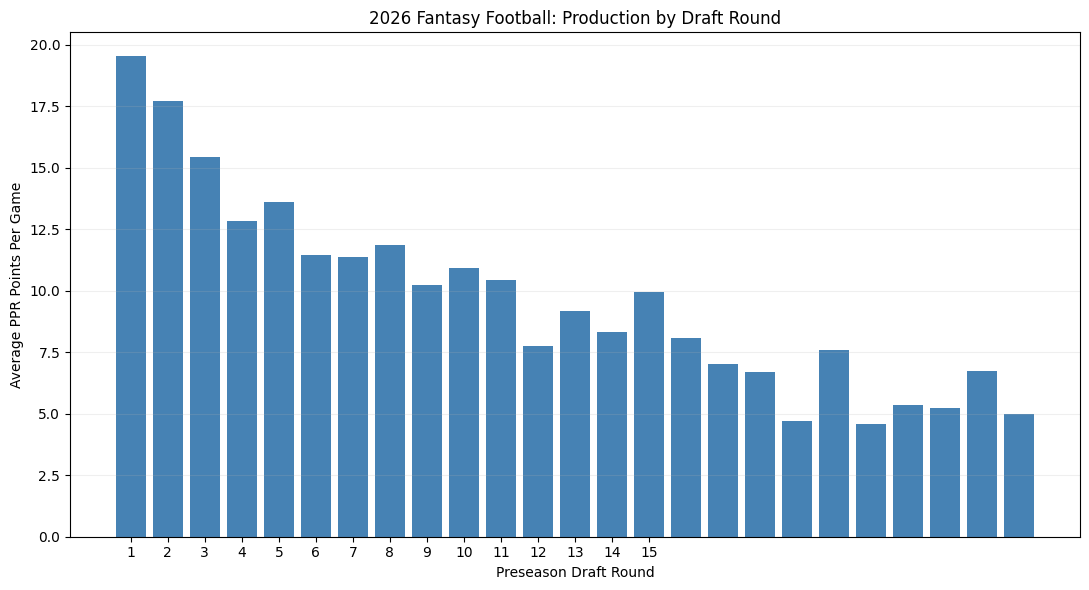

In [376]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    round_summary["draft_round"],
    round_summary["avg_points"],
    color="steelblue"
)

plt.title("2026 Fantasy Football: Production by Draft Round")
plt.xlabel("Preseason Draft Round")
plt.ylabel("Average PPR Points Per Game")
plt.xticks(range(1, 16))
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


## 5. Final Player Investment Model

In [377]:

import numpy as np

# Use our improved dataset
model_df = active_df.copy()

# Define replacement-level ranks
replacement_ranks = {
    "QB": 12,
    "RB": 24,
    "WR": 24,
    "TE": 12
}

# Calculate replacement scoring using points per week
replacement_points = {}

for position, rank in replacement_ranks.items():
    players = model_df[
        model_df["position"] == position
    ].sort_values("points_per_week", ascending=False)

    replacement_points[position] = players.iloc[rank - 1]["points_per_week"]

# Calculate value above replacement
model_df["replacement_ppw"] = model_df["position"].map(
    replacement_points
)

model_df["value_above_replacement"] = (
    model_df["points_per_week"] -
    model_df["replacement_ppw"]
)

# Calculate draft efficiency
model_df["draft_efficiency"] = (
    model_df["value_above_replacement"] *
    np.log1p(model_df["AVG"])
)

# Keep above-replacement players
model_df = model_df[
    model_df["value_above_replacement"] > 0
].copy()

# Normalize both metrics to 0-100
model_df["production_score"] = (
    100 * model_df["value_above_replacement"] /
    model_df["value_above_replacement"].max()
)

model_df["bargain_score"] = (
    100 * model_df["draft_efficiency"] /
    model_df["draft_efficiency"].max()
)

# Reward players who outperform their draft position
model_df["actual_rank"] = active_df.groupby("position")["points_per_week"].rank(ascending=False).reindex(model_df.index)

model_df["draft_rank"] = active_df.groupby("position")["AVG"].rank().reindex(model_df.index)

model_df["improvement"] = (
    model_df["draft_rank"] - model_df["actual_rank"]
).clip(lower=0)

model_df["improvement_score"] = (
    100 * model_df["improvement"] / max(model_df["improvement"].max(), 1)
)

# New investment score
model_df["investment_score"] = (
    0.50 * model_df["production_score"] +
    0.30 * model_df["improvement_score"] +
    0.20 * model_df["bargain_score"]
)

# Show top 15 investments
model_df[
    ["player", "position", "AVG",
     "points_per_week", "value_above_replacement",
     "investment_score"]
].sort_values(
    "investment_score", ascending=False
).head(15).round(2)


,player,position,AVG,points_per_week,value_above_replacement,investment_score
18,Kenneth Walker III,RB,20.0,23.00,14.10,68.49
7,Jaxon Smith-Njigba,WR,8.0,27.48,15.63,64.00
0,Jahmyr Gibbs,RB,1.5,25.62,16.72,57.45
149,Matthew Golden,WR,162.0,16.78,4.93,56.15
63,Christian Watson,WR,66.5,19.80,7.95,54.54
20,Kyren Williams,RB,21.5,19.83,10.93,53.61
76,Chuba Hubbard,RB,81.0,16.35,7.45,50.21
57,Jaylen Warren,RB,59.0,17.13,8.23,49.49
102,Isaiah Likely,TE,109.0,18.22,8.23,48.97
43,D'Andre Swift,RB,44.5,17.30,8.40,47.01


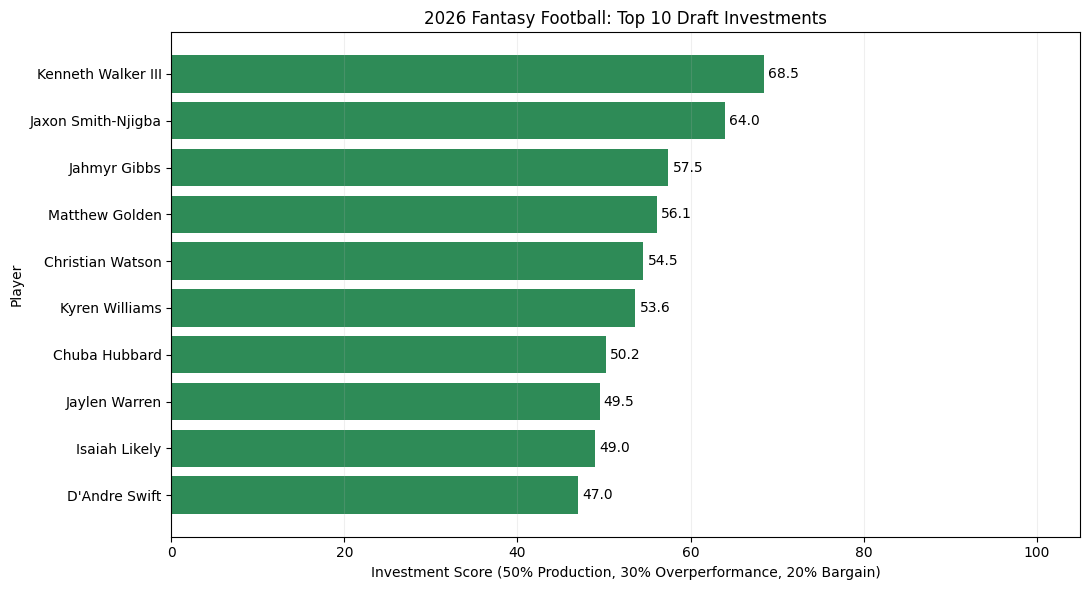

In [378]:

import matplotlib.pyplot as plt

top_10 = (
    model_df.nlargest(10, "investment_score")
    .sort_values("investment_score")
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top_10["player"],
    top_10["investment_score"],
    color="seagreen"
)

plt.bar_label(bars, fmt="%.1f", padding=3)

plt.title("2026 Fantasy Football: Top 10 Draft Investments")
plt.xlabel("Investment Score (50% Production, 30% Overperformance, 20% Bargain)")
plt.ylabel("Player")
plt.xlim(0, 105)
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


## 6. Key Findings

My model identified Kenneth Walker III, Jaxon Smith-Njigba, and Jahmyr Gibbs as the three best fantasy football draft investments so far in the 2026 season.

Kenneth Walker III ranked first with an investment score of 68.5, followed by Jaxon Smith-Njigba at 64.0 and Jahmyr Gibbs at 57.5.

One of the most interesting findings was Christian Watson ranking fifth with a score of 54.5 despite being drafted around the sixth round. Watson was drafted as approximately WR27 but is currently performing as WR3 in my dataset. This shows how valuable it can be to find players who significantly outperform their draft expectations.

Another interesting result was Matthew Golden ranking fourth with a score of 56.1. He improved from a positional draft ranking of WR55 to WR8, showing how later draft picks can provide unexpected value.

Overall, my analysis suggests that the best fantasy football investments aren't necessarily the players who score the most points. Draft cost and performance relative to expectations also matter. Similar to investing in the stock market, the goal is not just to identify valuable assets but to find assets that deliver strong returns relative to their initial cost.

## 7. Risk vs. Return Analysis

This section compares player investment scores with weekly scoring consistency. The goal is to identify players who provide strong draft value while also producing reliable fantasy performances.

In [379]:
# Calculate how much each player's weekly scores change
weekly_risk = fantasy_df.groupby("player_id")["fantasy_points_ppr"].std()

# Add the risk numbers to our investment model
risk_df = model_df.copy()

risk_df["weekly_risk"] = risk_df["player_id"].map(weekly_risk)

# Show the results
risk_df[
    ["player", "investment_score", "weekly_risk"]
].head(10).round(2)

,player,investment_score,weekly_risk
0,Jahmyr Gibbs,57.45,9.95
1,Bijan Robinson,42.78,11.55
2,Ja'Marr Chase,5.55,10.85
3,Christian McCaffrey,43.28,6.08
4,Jonathan Taylor,41.51,7.91
5,Puka Nacua,13.56,11.99
6,James Cook III,39.43,5.22
7,Jaxon Smith-Njigba,64.00,10.36
9,Omarion Hampton,2.87,4.87
10,Derrick Henry,45.23,9.84


In [380]:
# Mark weeks where a player scores under 10 points
fantasy_df["bad_week"] = fantasy_df["fantasy_points_ppr"] < 10

# Calculate the percentage of bad weeks for each player
bad_week_rate = fantasy_df.groupby("player_id")["bad_week"].mean() * 100

# Add downside risk to our investment data
risk_df["downside_risk"] = risk_df["player_id"].map(bad_week_rate)

# Show the top 10 investments
risk_df[
    ["player", "investment_score", "downside_risk"]
].sort_values(
    "investment_score", ascending=False
).head(10).round(2)

,player,investment_score,downside_risk
18,Kenneth Walker III,68.49,0.00
7,Jaxon Smith-Njigba,64.00,0.00
0,Jahmyr Gibbs,57.45,0.00
149,Matthew Golden,56.15,16.67
63,Christian Watson,54.54,33.33
20,Kyren Williams,53.61,16.67
76,Chuba Hubbard,50.21,0.00
57,Jaylen Warren,49.49,33.33
102,Isaiah Likely,48.97,33.33
43,D'Andre Swift,47.01,16.67


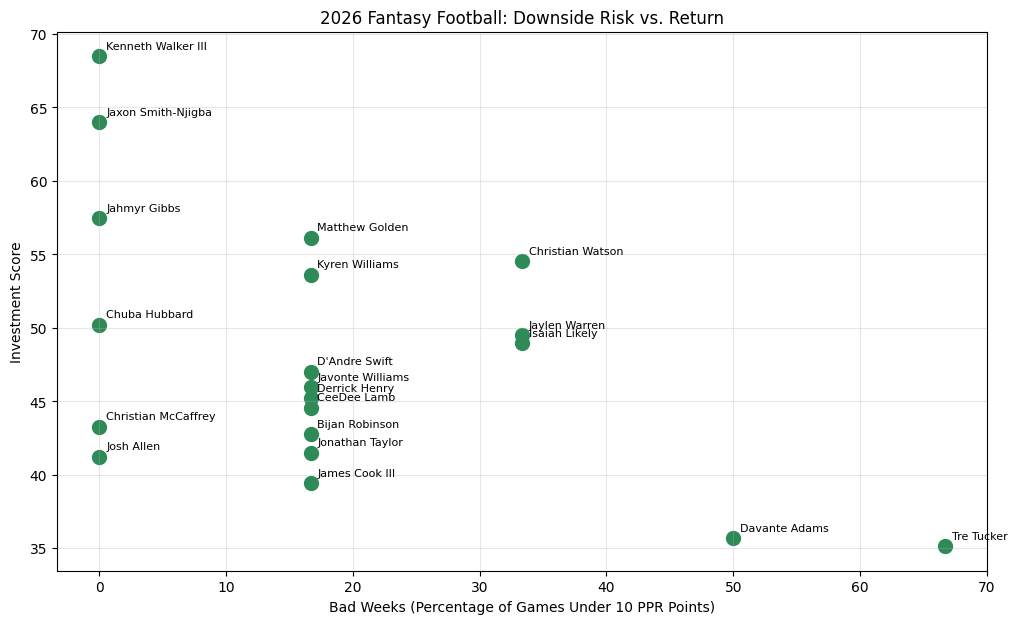

In [381]:
# Select the top 20 investments
top_players = risk_df.sort_values(
    "investment_score", ascending=False
).head(20)

plt.figure(figsize=(12, 7))

plt.scatter(
    top_players["downside_risk"],
    top_players["investment_score"],
    color="seagreen",
    s=100
)

# Label each player
for _, row in top_players.iterrows():
    plt.annotate(
        row["player"],
        (row["downside_risk"], row["investment_score"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Bad Weeks (Percentage of Games Under 10 PPR Points)")
plt.ylabel("Investment Score")
plt.title("2026 Fantasy Football: Downside Risk vs. Return")

plt.grid(alpha=0.3)
plt.show()

### Risk Analysis Findings

The risk analysis shows that a high investment score does not always mean a player is consistent. Some players provide strong draft value while rarely scoring below 10 fantasy points, while others have more frequent low-scoring performances. This is important because fantasy managers should consider both a player's return on draft investment and their reliability. Downside risk is measured using the percentage of recorded games below 10 PPR points, so missed games are not included in this calculation.

## 8. Conclusions and Limitations

### Conclusions

This project applied business and investment concepts to fantasy football by comparing preseason draft costs with actual player performance. Using a weighted investment score, I identified players who provided strong returns relative to their draft positions. I also analyzed scoring consistency and downside risk to better understand the relationship between value and reliability.

The results demonstrate that the highest-scoring fantasy players are not necessarily the best draft investments. Players selected later in drafts can provide greater value when their production exceeds expectations.

### Limitations

There are several limitations to this analysis:

- **Partial season data:** The model uses results from the first six weeks of the 2026 NFL season, so rankings may change as more games are played.
- **Subjective weighting:** The investment score uses 50% production, 30% draft overperformance, and 20% bargain value. These weights reflect my own assumptions rather than a statistically optimized formula.
- **Injuries and missed games:** The production model accounts for missed weeks, but the downside-risk calculation only includes games with recorded statistics.
- **Historical analysis:** The model evaluates performance so far and does not predict future fantasy production.

### Final Takeaway

Fantasy football draft decisions involve many of the same considerations as financial investments: initial cost, realized returns, and risk. By combining these factors, this project provides a structured way to evaluate which players have delivered the greatest value relative to their draft positions.